# Thực nghiệm A3, A4 — số mô phỏng & kiểu rollout (RQ1)

Issue **#14** (TV3). Notebook này chuẩn bị, chạy và phân tích hai thực nghiệm:

| Mã | Nội dung | Cấu hình |
|---|---|---|
| **A3** | MCTS 100 / 400 / 1600 / 6400 mô phỏng, đấu với Cấp 2 (luật) và Cấp 3 (Alpha-Beta) | `configs/experiments/a3_mcts_sims.yaml` |
| **A4** | MCTS rollout ngẫu nhiên vs rollout nhẹ (cùng 800 mô phỏng) | `configs/experiments/a4_rollout.yaml` |

Quy ước: mỗi khai cuộc chơi **2 ván đổi màu** → mỗi cặp tác tử có `2 × số khai cuộc` ván.
Kết quả ghi vào `runs/tournament/<tên thực nghiệm>/<thời điểm>/games.jsonl` (định dạng của arena).

> ⚠️ **Phụ thuộc:** #13 (MCTS) và #17 (arena). Arena đã có trên `main`; nếu #13 chưa merge,
> ô kiểm tra ngay dưới sẽ báo thiếu `caro/agents/mcts.py` và các ô chạy sẽ dừng trước khi tạo run.
>
> **Không cần chạy lại mô phỏng để phân tích:** các mục 3–5 chỉ đọc run đã có.


In [3]:
import copy
import json
import multiprocessing as mp
import os
import sys
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

# Tự tìm thư mục gốc project (chứa pyproject.toml), giống notebooks/analysis.ipynb
root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from caro.arena.stats import wilson
from caro.arena.tournament import worker_play
from caro.config import config_hash, load_config
from caro.runlog import Run

RUNS = Path("runs")
FIGS = Path("report/figures/thuc-nghiem")
FIGS.mkdir(parents=True, exist_ok=True)

# Bảng màu đã kiểm định CVD (dataviz): blue/orange trên nền sáng
C1, C2 = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
})

try:
    import caro.agents.mcts  # noqa: F401

    MCTS_OK = True
except ImportError as exc:  # ModuleNotFoundError khi #13 chưa merge
    MCTS_OK = False
    print("❌ Chưa có tác tử MCTS trên nhánh này:", exc)
    print("   → merge issue #13 (nhánh feat/l4-mcts) vào nhánh này rồi chạy lại:")
    print("     git fetch origin && git merge origin/feat/l4-mcts")

print("✅ Setup xong — project:", root)
print("   MCTS sẵn sàng:", MCTS_OK)


✅ Setup xong — project: /mnt/data/1_Projects/AAI/CaroGame
   MCTS sẵn sàng: True


## 1. Cấu hình & ước lượng chi phí

Đọc config đã ghép (defaults → file → override) để kiểm tra đúng tác tử, ngân sách và cách ghép cặp.
Sau đó ước lượng thời gian **trước khi chạy**: 6400 mô phỏng × nhiều ván × nhiều worker có thể mất hàng giờ,
nên cần quyết định số khai cuộc từ đầu và ghi lại nếu giảm.


In [4]:
EXP_A3 = "experiments/a3_mcts_sims"
EXP_A4 = "experiments/a4_rollout"
cfg_a3 = load_config(EXP_A3)
cfg_a4 = load_config(EXP_A4)


def describe(cfg):
    print(f"\n{cfg['experiment']['name']}  (hash {config_hash(cfg)})")
    for label, key in (("Challenger", "agents"), ("Baseline", "baselines")):
        for a in cfg[key]:
            lim = a["limits"]
            budget = f"max_sims={lim['max_sims']}" if lim.get("max_sims") else f"time_ms={lim.get('time_ms')}"
            extra = f", rollout={a['params'].get('rollout')}" if a["kind"] == "mcts" else ""
            print(f"  {label:10s} {a['id']:16s} kind={a['kind']:10s} {budget}{extra}")
    print(
        f"  pairs={cfg['arena'].get('pairs')} · workers={cfg['arena'].get('workers')} · "
        f"seed={cfg['seed']} · openings={cfg['arena']['openings']['count']}"
    )


describe(cfg_a3)
describe(cfg_a4)



a3_mcts_sims  (hash 5232b5066240)
  Challenger MCTS-100         kind=mcts       max_sims=100, rollout=random
  Challenger MCTS-400         kind=mcts       max_sims=400, rollout=random
  Challenger MCTS-1600        kind=mcts       max_sims=1600, rollout=random
  Challenger MCTS-6400        kind=mcts       max_sims=6400, rollout=random
  Baseline   L2-Rule          kind=rule_based max_sims=800
  Baseline   L3-AlphaBeta     kind=alphabeta  max_sims=800
  pairs=challengers_vs_baselines · workers=4 · seed=2026 · openings=100

a4_rollout  (hash b764a9a30bdc)
  Challenger MCTS-random      kind=mcts       max_sims=800, rollout=random
  Challenger MCTS-light       kind=mcts       max_sims=800, rollout=light
  Baseline   L2-Rule          kind=rule_based max_sims=800
  Baseline   L3-AlphaBeta     kind=alphabeta  max_sims=800
  pairs=challengers_vs_baselines · workers=4 · seed=2026 · openings=100


In [5]:
OPENINGS_PATH = Path(cfg_a3["arena"]["openings"]["file"])
ALL_OPENINGS = json.loads(OPENINGS_PATH.read_text(encoding="utf-8"))
assert len(ALL_OPENINGS) == 100, f"Kỳ vọng 100 khai cuộc, thấy {len(ALL_OPENINGS)}"

# ===== THAM SỐ CHẠY — sửa ở đây =====
N_OPENINGS = 100      # mỗi khai cuộc chơi 2 ván đổi màu; giảm nếu cần chạy nhanh
WORKERS = 4           # số tiến trình; nên <= số nhân CPU thực
AVG_PLIES = 45        # ước lượng số nước/ván, chỉ dùng để ước lượng chi phí
SIMS_PER_SEC = {"random": 8500, "light": 2400}          # đo trên máy này ở issue #13
BASELINE_S_PER_MOVE = {"L2-Rule": 0.01, "L3-AlphaBeta": 0.35}  # ước lượng thô


def estimate_cost(cfg, n_openings):
    rows = []
    for a in cfg["agents"]:
        sims = a["limits"].get("max_sims") or 0
        rollout = a["params"].get("rollout", "random")
        rate = SIMS_PER_SEC.get(rollout, 1.0)
        for b in cfg["baselines"]:
            games = 2 * n_openings
            moves = max(1.0, (AVG_PLIES - 3) / 2)   # mỗi bên đi ~nửa số nước
            sec = moves * (sims / rate + BASELINE_S_PER_MOVE.get(b["id"], 0.05))
            rows.append({
                "Tác tử": a["id"],
                "Đối thủ": b["id"],
                "Số ván": games,
                "Mô phỏng/nước": sims,
                "Mô phỏng/giây": int(rate),
                "Ước lượng (phút)": round(games * sec / 60 / WORKERS, 1),
            })
    return pd.DataFrame(rows)


cost_a3 = estimate_cost(cfg_a3, N_OPENINGS)
cost_a4 = estimate_cost(cfg_a4, N_OPENINGS)
print("A3 — ước lượng chi phí")
display(cost_a3)
print("A4 — ước lượng chi phí")
display(cost_a4)
print(
    f"\nA3: {cost_a3['Số ván'].sum()} ván, ước lượng ~{cost_a3['Ước lượng (phút)'].sum():.0f} phút "
    f"trên {WORKERS} workers"
)
print(
    f"A4: {cost_a4['Số ván'].sum()} ván, ước lượng ~{cost_a4['Ước lượng (phút)'].sum():.0f} phút "
    f"trên {WORKERS} workers"
)
print("\nLưu ý: ước lượng ±50%, chưa tính thời gian khởi động worker và I/O log.")
if N_OPENINGS < cfg_a3["arena"]["openings"]["count"]:
    print(
        f"⚠️  ĐÃ GIẢM SỐ KHAI CUỘC: {N_OPENINGS}/{cfg_a3['arena']['openings']['count']} "
        "→ phải ghi lại trong báo cáo."
    )


A3 — ước lượng chi phí


,Tác tử,Đối thủ,Số ván,Mô phỏng/nước,Mô phỏng/giây,Ước lượng (phút)
0,MCTS-100,L2-Rule,200,100,8500,0.4
1,MCTS-100,L3-AlphaBeta,200,100,8500,6.3
2,MCTS-400,L2-Rule,200,400,8500,1.0
3,MCTS-400,L3-AlphaBeta,200,400,8500,6.9
4,MCTS-1600,L2-Rule,200,1600,8500,3.5
5,MCTS-1600,L3-AlphaBeta,200,1600,8500,9.4
6,MCTS-6400,L2-Rule,200,6400,8500,13.4
7,MCTS-6400,L3-AlphaBeta,200,6400,8500,19.3


A4 — ước lượng chi phí


,Tác tử,Đối thủ,Số ván,Mô phỏng/nước,Mô phỏng/giây,Ước lượng (phút)
0,MCTS-random,L2-Rule,200,800,8500,1.8
1,MCTS-random,L3-AlphaBeta,200,800,8500,7.8
2,MCTS-light,L2-Rule,200,800,2400,6.0
3,MCTS-light,L3-AlphaBeta,200,800,2400,12.0



A3: 1600 ván, ước lượng ~60 phút trên 4 workers
A4: 800 ván, ước lượng ~28 phút trên 4 workers

Lưu ý: ước lượng ±50%, chưa tính thời gian khởi động worker và I/O log.


## 2. Dựng cặp đấu & chạy

`caro.arena.tournament` hiện chỉ round-robin trong `agents` và **chưa đọc `arena.pairs`**, nên notebook
tự dựng đúng cặp `challengers_vs_baselines` như config yêu cầu, rồi dùng lại `worker_play` của arena
(hàm cấp module, pickle được cho `ProcessPoolExecutor`) để chạy song song và ghi log chuẩn.

Mỗi khai cuộc sinh 2 ván: challenger cầm X và challenger cầm O. `play_match` tự suy seed từ
`(seed gốc, game_id, màu)` nên hai ván không trùng seed.


In [6]:
def build_matches(cfg, n_openings):
    """Danh sách (game_id, agent_x_cfg, agent_o_cfg, opening_id, opening_moves, seed)."""
    openings = ALL_OPENINGS[:n_openings]
    matches, gid = [], 0
    for challenger in cfg["agents"]:
        for baseline in cfg["baselines"]:
            for opening_id, opening in enumerate(openings):
                matches.append((gid, challenger, baseline, opening_id, opening, cfg["seed"]))
                gid += 1
                matches.append((gid, baseline, challenger, opening_id, opening, cfg["seed"]))
                gid += 1
    return matches


m3 = build_matches(cfg_a3, N_OPENINGS)
m4 = build_matches(cfg_a4, N_OPENINGS)
print(f"A3: {len(m3)} ván · A4: {len(m4)} ván")
print("Ví dụ 2 ván đầu A3:", [(x[0], x[1]["id"], x[2]["id"], x[3]) for x in m3[:2]])


A3: 1600 ván · A4: 800 ván
Ví dụ 2 ván đầu A3: [(0, 'MCTS-100', 'L2-Rule', 0), (1, 'L2-Rule', 'MCTS-100', 0)]


In [7]:
def run_pairs(cfg, matches, label, n_openings, workers):
    """Chạy `matches` bằng worker_play của arena, ghi games.jsonl qua Run.

    Config được sao chép và ghi đè `arena.num_openings` / `openings.count` / `workers`
    để config.yaml trong run phản ánh đúng phần đã chạy (kể cả khi giảm số ván).
    """
    cfg = copy.deepcopy(cfg)
    cfg["arena"]["num_openings"] = n_openings
    cfg["arena"]["openings"]["count"] = n_openings
    cfg["arena"]["workers"] = workers

    total = len(matches)
    scores = {}
    failed = 0
    done = 0
    t0 = time.perf_counter()

    with Run(cfg) as run:
        run.log.info(
            "%s: %d ván, %d workers, %d/%d khai cuộc",
            label, total, workers, n_openings, cfg["arena"]["openings"]["count"],
        )
        run.log_metric(
            0, planned_games=total, n_openings=n_openings, workers=workers,
            avg_plies_assumed=AVG_PLIES,
        )
        step = max(1, total // 100)
        # Dùng fork khi có (Linux): worker không phải import lại __main__ của kernel.
        mp_context = mp.get_context("fork") if hasattr(os, "fork") else None
        executor = ProcessPoolExecutor(max_workers=workers, mp_context=mp_context)
        try:
            futures = {executor.submit(worker_play, m): m for m in matches}
            for fut in as_completed(futures):
                try:
                    res = fut.result()
                except Exception as exc:   # noqa: BLE001 - một ván lỗi không làm hỏng cả thực nghiệm
                    failed += 1
                    done += 1
                    run.log.error("Ván lỗi (%d): %s", failed, exc)
                    continue

                res["tournament_id"] = run.id
                ax, ao = res["agent_x"], res["agent_o"]
                scores.setdefault(ax, 0.0)
                scores.setdefault(ao, 0.0)
                if res["result"] == 1:
                    scores[ax] += 1.0
                elif res["result"] == -1:
                    scores[ao] += 1.0
                else:
                    scores[ax] += 0.5
                    scores[ao] += 0.5

                run.log_game(res)
                done += 1
                if done % step == 0 or done == total:
                    elapsed = time.perf_counter() - t0
                    eta = elapsed / done * (total - done)
                    msg = (
                        f"{done:4d}/{total} ván · {elapsed / 60:5.1f} phút · "
                        f"còn ~{eta / 60:4.1f} phút"
                    )
                    print("\r" + msg, end="", flush=True)
                    if done % (step * 5) == 0 or done == total:
                        run.log.info(msg.strip())
        except KeyboardInterrupt:
            # Huỷ các ván chưa chạy; ván đang chạy sẽ kết thúc (tối đa ~1 ván/worker).
            executor.shutdown(wait=True, cancel_futures=True)
            run.log.warning("Dừng bởi người dùng sau %d/%d ván", done, total)
            run.finish(
                status="interrupted", score=scores, n_openings=n_openings,
                planned_games=total, failed_games=failed,
            )
            raise
        finally:
            executor.shutdown(wait=True, cancel_futures=True)

        print()
        print("Điểm tổng (góc nhìn X):", scores)
        if failed:
            print(f"⚠️  {failed} ván lỗi — xem run.log; phân tích chỉ dùng các ván đã ghi.")
        run.finish(
            status="ok", score=scores, n_openings=n_openings,
            planned_games=total, failed_games=failed, workers=workers,
        )
        run.log.info("Điểm tổng: %s", scores)
        print("Run:", run.dir)

    return run.dir


### Chạy A3

Ước lượng ở mục 1 là cơ sở để quyết định `N_OPENINGS`. Theo dõi dòng tiến độ trong ô dưới;
`Ctrl-C` dừng sau khi các ván đang chạy xong và đánh dấu run `interrupted`.

> Run A3 chỉ nên chạy khi `MCTS_OK=True`. Nếu #13 chưa merge, ô này báo lỗi rõ ràng và không tạo run.


In [8]:
RUN_A3 = True

if RUN_A3:
    if not MCTS_OK:
        raise RuntimeError("Chưa có caro/agents/mcts.py — merge issue #13 trước khi chạy A3.")
    RUN_DIR_A3 = run_pairs(cfg_a3, m3, "A3", N_OPENINGS, WORKERS)
else:
    RUN_DIR_A3 = None
    print("Bỏ qua A3 (RUN_A3=False)")


2026-11-14 23:23:53 INFO    run tournament/a3_mcts_sims/20261114-232353 — config experiments/a3_mcts_sims, seed 2026
2026-11-14 23:23:53 INFO    A3: 1600 ván, 4 workers, 100/100 khai cuộc


  80/1600 ván ·   0.0 phút · còn ~ 0.5 phút

2026-11-14 23:23:54 INFO    80/1600 ván ·   0.0 phút · còn ~ 0.5 phút


 160/1600 ván ·   0.0 phút · còn ~ 0.4 phút

2026-11-14 23:23:56 INFO    160/1600 ván ·   0.0 phút · còn ~ 0.4 phút


 240/1600 ván ·   0.3 phút · còn ~ 1.9 phút

... (96 outputs left out)

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 585, in _log_error
    self.closed()
            ~~~^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 372, in dispatch_control
    await self.process_control(msg)
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 378, in process_control
    idents, msg = self.session.feed_identities(msg, copy=False)
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/da

1600/1600 ván ·  22.1 phút · còn ~ 0.0 phút

2026-11-14 23:45:56 INFO    1600/1600 ván ·  22.1 phút · còn ~ 0.0 phút
2026-11-14 23:45:56 INFO    kết thúc: ok sau 1323.1 s



Điểm tổng (góc nhìn X): {'L2-Rule': 785.0, 'MCTS-100': 0.0, 'L3-AlphaBeta': 796.0, 'MCTS-400': 0.0, 'MCTS-1600': 0.0, 'MCTS-6400': 19.0}
Run: /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a3_mcts_sims/20261114-232353


### Chạy A4

A4 dùng cùng 800 mô phỏng cho cả hai kiểu rollout (thừa hưởng `budgets/mode_b_fixed`),
chỉ đổi `params.rollout` — đúng yêu cầu "giữ nguyên số mô phỏng".


In [9]:
RUN_A4 = True

if RUN_A4:
    if not MCTS_OK:
        raise RuntimeError("Chưa có caro/agents/mcts.py — merge issue #13 trước khi chạy A4.")
    RUN_DIR_A4 = run_pairs(cfg_a4, m4, "A4", N_OPENINGS, WORKERS)
else:
    RUN_DIR_A4 = None
    print("Bỏ qua A4 (RUN_A4=False)")


2026-11-14 23:45:56 INFO    run tournament/a4_rollout/20261114-234556 — config experiments/a4_rollout, seed 2026
2026-11-14 23:45:56 INFO    A4: 800 ván, 4 workers, 100/100 khai cuộc


  40/800 ván ·   0.1 phút · còn ~ 1.9 phút

2026-11-14 23:46:02 INFO    40/800 ván ·   0.1 phút · còn ~ 1.9 phút


  80/800 ván ·   0.2 phút · còn ~ 1.7 phút

2026-11-14 23:46:07 INFO    80/800 ván ·   0.2 phút · còn ~ 1.7 phút


 120/800 ván ·   0.3 phút · còn ~ 1.6 phút

... (58 outputs left out)

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 585, in _log_error
    self.closed()
            ~~~^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 372, in dispatch_control
    await self.process_control(msg)
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 378, in process_control
    idents, msg = self.session.feed_identities(msg, copy=False)
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/da

 800/800 ván ·   8.8 phút · còn ~ 0.0 phút

2026-11-14 23:54:42 INFO    800/800 ván ·   8.8 phút · còn ~ 0.0 phút
2026-11-14 23:54:42 INFO    kết thúc: ok sau 526.1 s



Điểm tổng (góc nhìn X): {'L2-Rule': 400.0, 'MCTS-random': 0.0, 'L3-AlphaBeta': 400.0, 'MCTS-light': 0.0}
Run: /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a4_rollout/20261114-234556


## 3. Phân tích run đã có

Các ô dưới **chỉ đọc** `runs/tournament/.../games.jsonl`, không chạy lại mô phỏng.
Đặt `RUN_DIR_A3` / `RUN_DIR_A4` thành một đường dẫn cụ thể nếu muốn phân tích run cũ;
để `None` thì tự lấy run mới nhất.

**Lưu ý kỹ thuật về thời gian/nước:** `play_match` ghi `time_ms[]` / `sims[]` bắt đầu từ nước
đầu **sau khai cuộc**. Khai cuộc trong `openings_v1.json` dài 2–4 nước, nên phần tử 0 không luôn
thuộc về X. Vì vậy notebook tính `opening_len = len(moves) - len(time_ms)` cho từng ván rồi suy
đúng bên đi, thay vì dùng trực tiếp `stats.calculate_performance` (hàm này giả định khai cuộc dài
chẵn và sẽ gán nhầm thời gian khi khai cuộc dài 3 nước).


In [10]:
RUN_DIR_A3 = globals().get("RUN_DIR_A3")
RUN_DIR_A4 = globals().get("RUN_DIR_A4")


def latest_run(exp_name):
    base = RUNS / "tournament" / exp_name
    if not base.exists():
        return None
    link = base / "latest"
    if link.exists():
        return link.resolve()
    dirs = sorted(p for p in base.iterdir() if p.is_dir() and p.name != "latest")
    return dirs[-1] if dirs else None


def load_games(run_dir):
    if run_dir is None:
        return pd.DataFrame()
    path = Path(run_dir) / "games.jsonl"
    if not path.exists():
        print("Không thấy", path)
        return pd.DataFrame()
    records = [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    df = pd.DataFrame(records)
    print(f"Đọc {len(df)} ván từ {path}")
    if df.empty:
        return df
    if "moves" not in df.columns or "time_ms" not in df.columns:
        print("⚠️ Thiếu moves/time_ms — cần log.per_move_stats: true")
        return df
    df["opening_len"] = df.apply(lambda r: len(r["moves"]) - len(r["time_ms"]), axis=1)
    return df


run_a3 = Path(RUN_DIR_A3) if RUN_DIR_A3 else latest_run(cfg_a3["experiment"]["name"])
run_a4 = Path(RUN_DIR_A4) if RUN_DIR_A4 else latest_run(cfg_a4["experiment"]["name"])
print("Run A3:", run_a3)
print("Run A4:", run_a4)
df_a3 = load_games(run_a3)
df_a4 = load_games(run_a4)


Run A3: /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a3_mcts_sims/20261114-232353
Run A4: /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a4_rollout/20261114-234556
Đọc 1600 ván từ /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a3_mcts_sims/20261114-232353/games.jsonl
Đọc 800 ván từ /mnt/data/1_Projects/AAI/CaroGame/runs/tournament/a4_rollout/20261114-234556/games.jsonl


In [11]:
def outcome_for(row, agent):
    """Điểm của `agent` trong 1 ván: 1 thắng, 0.5 hoà, 0 thua."""
    if row["agent_x"] == agent:
        return 1.0 if row["result"] == 1 else (0.5 if row["result"] == 0 else 0.0)
    if row["agent_o"] == agent:
        return 1.0 if row["result"] == -1 else (0.5 if row["result"] == 0 else 0.0)
    raise ValueError(f"{agent} không có trong ván")


def head_to_head(df, agent, opponent):
    """Điểm, W-D-L và KTC Wilson 95% của `agent` trước `opponent` (gộp cả hai màu)."""
    if df.empty:
        return {"n": 0, "wins": 0, "draws": 0, "losses": 0, "score": float("nan"),
                    "ci_low": float("nan"), "ci_high": float("nan")}
    games = df[
        ((df["agent_x"] == agent) & (df["agent_o"] == opponent))
        | ((df["agent_x"] == opponent) & (df["agent_o"] == agent))
    ]
    points = [outcome_for(r, agent) for _, r in games.iterrows()]
    wins = sum(p == 1.0 for p in points)
    draws = sum(p == 0.5 for p in points)
    losses = sum(p == 0.0 for p in points)
    n = len(points)
    score = (wins + 0.5 * draws) / n if n else float("nan")
    low, high = wilson(wins + 0.5 * draws, n) if n else (float("nan"), float("nan"))
    return {"n": n, "wins": wins, "draws": draws, "losses": losses, "score": score,
                "ci_low": low, "ci_high": high}


def per_move_stats(df, agent):
    """Thời gian/nước và mô phỏng/giây của `agent`, xử lý đúng parity của khai cuộc 2–4 nước."""
    times, sims = [], []
    for _, row in df.iterrows():
        if agent not in (row["agent_x"], row["agent_o"]):
            continue
        tlist = row["time_ms"] if isinstance(row["time_ms"], list) else []
        slist = row["sims"] if isinstance(row["sims"], list) else []
        opening_len = len(row["moves"]) - len(tlist)
        for i, t in enumerate(tlist):
            side = (opening_len + i) % 2          # 0 = X, 1 = O
            mover = row["agent_x"] if side == 0 else row["agent_o"]
            if mover != agent:
                continue
            times.append(float(t))
            if i < len(slist):
                sims.append(float(slist[i]))
    if not times:
        return {"moves": 0, "time_mean_ms": float("nan"), "time_p95_ms": float("nan"),
                    "sims_per_s": float("nan"), "total_s": 0.0}
    total_s = sum(times) / 1000.0
    return {
        "moves": len(times),
        "time_mean_ms": float(np.mean(times)),
        "time_p95_ms": float(np.percentile(times, 95)),
        "sims_per_s": (sum(sims) / total_s) if total_s > 0 else float("nan"),
        "total_s": total_s,
    }


### Bảng 06.3 — A3

Mỗi dòng là một mức mô phỏng; mỗi đối thủ có điểm kèm KTC Wilson 95% và W-D-L.
Thời gian/nước và mô phỏng/giây tính trên toàn bộ nước đi của tác tử trong mọi ván.


In [12]:
def table_experiment(df, cfg):
    if df.empty:
        print("Chưa có dữ liệu — chạy mục 2 trước hoặc trỏ RUN_DIR_* vào run cũ.")
        return pd.DataFrame()
    show_rollout = len({a["params"].get("rollout") for a in cfg["agents"]}) > 1
    rows = []
    for a in cfg["agents"]:
        row = {"Tác tử": a["id"], "Mô phỏng": a["limits"].get("max_sims")}
        if show_rollout:
            row["Rollout"] = a["params"].get("rollout")
        for b in cfg["baselines"]:
            h = head_to_head(df, a["id"], b["id"])
            row[f"Điểm vs {b['id']}"] = (
                f"{h['score']:.3f} [{h['ci_low']:.3f}, {h['ci_high']:.3f}]"
                f" (W{h['wins']}-D{h['draws']}-L{h['losses']}, n={h['n']})"
            )
        p = per_move_stats(df, a["id"])
        row["TG/nước TB (ms)"] = None if np.isnan(p["time_mean_ms"]) else round(p["time_mean_ms"], 1)
        row["TG/nước p95 (ms)"] = None if np.isnan(p["time_p95_ms"]) else round(p["time_p95_ms"], 1)
        row["Mô phỏng/giây"] = None if np.isnan(p["sims_per_s"]) else round(p["sims_per_s"])
        rows.append(row)
    return pd.DataFrame(rows)


tbl_a3 = table_experiment(df_a3, cfg_a3)
print("Bảng 06.3 — A3: điểm vs Cấp 2 / Cấp 3 (KTC Wilson 95%)")
display(tbl_a3)
print(tbl_a3.to_string(index=False))


Bảng 06.3 — A3: điểm vs Cấp 2 / Cấp 3 (KTC Wilson 95%)


,Tác tử,Mô phỏng,Điểm vs L2-Rule,Điểm vs L3-AlphaBeta,TG/nước TB (ms),TG/nước p95 (ms),Mô phỏng/giây
0,MCTS-100,100,"0.000 [0.000, 0.019] (W0-D0-L200, n=200)","0.000 [0.000, 0.019] (W0-D0-L200, n=200)",16.4,22.3,6112
1,MCTS-400,400,"0.000 [0.000, 0.019] (W0-D0-L200, n=200)","0.000 [0.000, 0.019] (W0-D0-L200, n=200)",68.9,85.3,5807
2,MCTS-1600,1600,"0.000 [0.000, 0.019] (W0-D0-L200, n=200)","0.000 [0.000, 0.019] (W0-D0-L200, n=200)",298.5,359.6,5360
3,MCTS-6400,6400,"0.075 [0.046, 0.120] (W15-D0-L185, n=200)","0.020 [0.008, 0.050] (W4-D0-L196, n=200)",1204.6,1467.2,5313


   Tác tử  Mô phỏng                           Điểm vs L2-Rule                     Điểm vs L3-AlphaBeta  TG/nước TB (ms)  TG/nước p95 (ms)  Mô phỏng/giây
 MCTS-100       100  0.000 [0.000, 0.019] (W0-D0-L200, n=200) 0.000 [0.000, 0.019] (W0-D0-L200, n=200)             16.4              22.3           6112
 MCTS-400       400  0.000 [0.000, 0.019] (W0-D0-L200, n=200) 0.000 [0.000, 0.019] (W0-D0-L200, n=200)             68.9              85.3           5807
MCTS-1600      1600  0.000 [0.000, 0.019] (W0-D0-L200, n=200) 0.000 [0.000, 0.019] (W0-D0-L200, n=200)            298.5             359.6           5360
MCTS-6400      6400 0.075 [0.046, 0.120] (W15-D0-L185, n=200) 0.020 [0.008, 0.050] (W4-D0-L196, n=200)           1204.6            1467.2           5313


### Biểu đồ A3 — điểm theo log₂(số mô phỏng)

Câu hỏi bão hoà: tăng 4× số mô phỏng lần cuối (1600 → 6400) còn cải thiện đáng kể không?
Biểu đồ dùng thang log₂ để bốn mức 100 / 400 / 1600 / 6400 cách đều nhau.


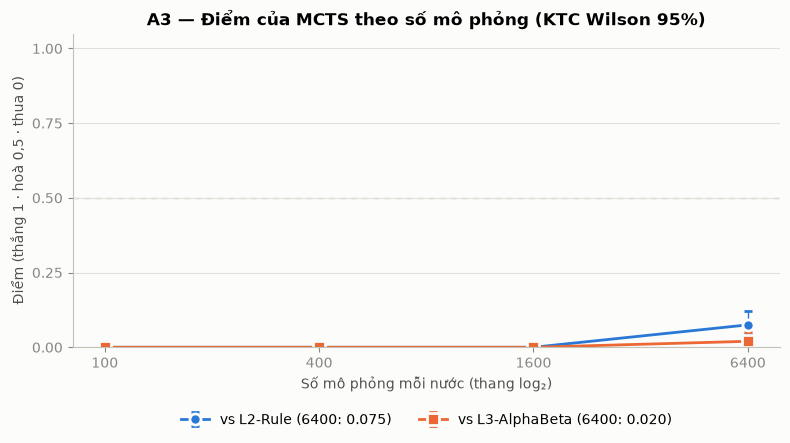

Lưu: report/figures/thuc-nghiem/a3_diem_theo_sims.png


In [13]:
def plot_score_vs_sims(df, cfg, out_path):
    if df.empty:
        print("Chưa có dữ liệu A3 — chạy mục 2 trước hoặc trỏ RUN_DIR_A3 vào run cũ.")
        return
    if not any(head_to_head(df, a["id"], b["id"])["n"] for a in cfg["agents"] for b in cfg["baselines"]):
        print("Run không khớp tác tử trong config — kiểm tra RUN_DIR_A3.")
        return
    sims = [a["limits"]["max_sims"] for a in cfg["agents"]]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for baseline, color, marker in zip(cfg["baselines"], (C1, C2), ("o", "s")):
        stats = [head_to_head(df, a["id"], baseline["id"]) for a in cfg["agents"]]
        scores = [h["score"] for h in stats]
        lower = [h["score"] - h["ci_low"] for h in stats]
        upper = [h["ci_high"] - h["score"] for h in stats]
        last = scores[-1]
        ax.errorbar(
            sims, scores, yerr=[lower, upper],
            color=color, marker=marker, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2,
            linewidth=2, capsize=3, elinewidth=1,
            label=f"vs {baseline['id']} ({sims[-1]}: {last:.3f})",
        )
    ax.axhline(0.5, color=AXIS, linewidth=1, linestyle=(0, (4, 4)), zorder=0)
    ax.set_xscale("log", base=2)
    ax.set_xticks(sims)
    ax.set_xticklabels([str(s) for s in sims])
    ax.minorticks_off()
    ax.set_xlabel("Số mô phỏng mỗi nước (thang log₂)")
    ax.set_ylabel("Điểm (thắng 1 · hoà 0,5 · thua 0)")
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.grid(True, axis="y", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
    ax.set_title("A3 — Điểm của MCTS theo số mô phỏng (KTC Wilson 95%)")
    fig.tight_layout()
    fig.savefig(out_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Lưu:", out_path)


plot_score_vs_sims(df_a3, cfg_a3, FIGS / "a3_diem_theo_sims.png")


### Kiểm tra bão hoà (A3)

Với mỗi đối thủ, so sánh điểm ở hai mức liên tiếp (100→400→1600→6400).
Coi là **bão hoà** khi mức tăng cuối nhỏ (< 0,03) **và** hai KTC chồng lấn — tức là thêm
mô phỏng không còn tạo khác biệt vượt nhiễu thống kê.


In [14]:
def saturation_table(df, cfg):
    if df.empty:
        return pd.DataFrame()
    rows = []
    for baseline in cfg["baselines"]:
        stats = [
            (a["id"], a["limits"]["max_sims"], head_to_head(df, a["id"], baseline["id"]))
            for a in cfg["agents"]
        ]
        for (_, s0, h0), (_, s1, h1) in itertools.pairwise(stats):
            overlap = not (h1["ci_low"] > h0["ci_high"] or h1["ci_high"] < h0["ci_low"])
            rows.append({
                "Đối thủ": baseline["id"],
                "Từ": s0,
                "Đến": s1,
                "Δ điểm": round(h1["score"] - h0["score"], 3),
                "KTC chồng lấn": "có" if overlap else "không",
            })
    return pd.DataFrame(rows)


sat_a3 = saturation_table(df_a3, cfg_a3)
display(sat_a3)


,Đối thủ,Từ,Đến,Δ điểm,KTC chồng lấn
0,L2-Rule,100,400,0.000,có
1,L2-Rule,400,1600,0.000,có
2,L2-Rule,1600,6400,0.075,không
3,L3-AlphaBeta,100,400,0.000,có
4,L3-AlphaBeta,400,1600,0.000,có
5,L3-AlphaBeta,1600,6400,0.020,có


In [15]:
def conclusion_a3(df, cfg, sat):
    if df.empty or sat.empty:
        print("Chưa có dữ liệu để kết luận A3.")
        return
    for baseline in cfg["baselines"]:
        sub = sat[sat["Đối thủ"] == baseline["id"]].reset_index(drop=True)
        last = sub.iloc[-1]
        saturated = abs(last["Δ điểm"]) < 0.03 and last["KTC chồng lấn"] == "có"
        scores = [
            (a["limits"]["max_sims"], head_to_head(df, a["id"], baseline["id"])["score"])
            for a in cfg["agents"]
        ]
        curve = " → ".join(f"{s}: {v:.3f}" for s, v in scores)
        print(
            f"- vs {baseline['id']}: {curve}\n"
            f"  Mức tăng cuối ({last['Từ']}→{last['Đến']}) = {last['Δ điểm']:+.3f}, "
            f"KTC {'chồng lấn' if last['KTC chồng lấn'] == 'có' else 'tách rời'} "
            f"→ {'BÃO HOÀ' if saturated else 'CÒN CẢI THIỆN'}"
        )


print("Kết luận A3 (dùng cho RQ1):")
conclusion_a3(df_a3, cfg_a3, sat_a3)


Kết luận A3 (dùng cho RQ1):
- vs L2-Rule: 100: 0.000 → 400: 0.000 → 1600: 0.000 → 6400: 0.075
  Mức tăng cuối (1600→6400) = +0.075, KTC tách rời → CÒN CẢI THIỆN
- vs L3-AlphaBeta: 100: 0.000 → 400: 0.000 → 1600: 0.000 → 6400: 0.020
  Mức tăng cuối (1600→6400) = +0.020, KTC chồng lấn → BÃO HOÀ


## 4. A4 — kiểu rollout (random vs light)

A4 giữ nguyên **800 mô phỏng** cho cả hai tác tử, chỉ đổi `params.rollout`.
Rollout `light` ưu tiên thắng ngay → chặn thua ngay → ngẫu nhiên, nên chậm hơn nhưng có thể
chơi tốt hơn ở cùng ngân sách mô phỏng.


In [16]:
tbl_a4 = table_experiment(df_a4, cfg_a4)
print("A4 — rollout random vs light (800 mô phỏng, KTC Wilson 95%)")
display(tbl_a4)
print(tbl_a4.to_string(index=False))


A4 — rollout random vs light (800 mô phỏng, KTC Wilson 95%)


,Tác tử,Mô phỏng,Rollout,Điểm vs L2-Rule,Điểm vs L3-AlphaBeta,TG/nước TB (ms),TG/nước p95 (ms),Mô phỏng/giây
0,MCTS-random,800,random,"0.000 [0.000, 0.019] (W0-D0-L200, n=200)","0.000 [0.000, 0.019] (W0-D0-L200, n=200)",147.2,177.8,5435
1,MCTS-light,800,light,"0.000 [0.000, 0.019] (W0-D0-L200, n=200)","0.000 [0.000, 0.019] (W0-D0-L200, n=200)",551.7,745.8,1450


     Tác tử  Mô phỏng Rollout                          Điểm vs L2-Rule                     Điểm vs L3-AlphaBeta  TG/nước TB (ms)  TG/nước p95 (ms)  Mô phỏng/giây
MCTS-random       800  random 0.000 [0.000, 0.019] (W0-D0-L200, n=200) 0.000 [0.000, 0.019] (W0-D0-L200, n=200)            147.2             177.8           5435
 MCTS-light       800   light 0.000 [0.000, 0.019] (W0-D0-L200, n=200) 0.000 [0.000, 0.019] (W0-D0-L200, n=200)            551.7             745.8           1450


### Biểu đồ A4 — điểm kèm KTC (dot plot)

Bốn ước lượng (2 kiểu rollout × 2 đối thủ) với thanh sai số Wilson 95%.
Dot plot phù hợp hơn cột vì đại lượng cần so sánh là **ước lượng kèm bất định**, không phải độ lớn cộng dồn.


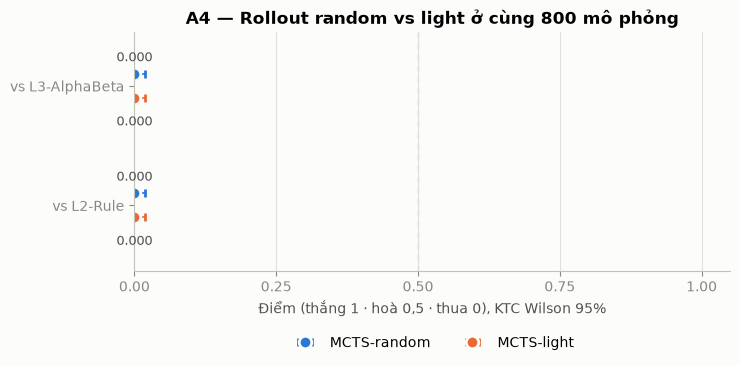

Lưu: report/figures/thuc-nghiem/a4_rollout.png


In [17]:
def plot_a4(df, cfg, out_path):
    if df.empty:
        print("Chưa có dữ liệu A4 — chạy mục 2 trước hoặc trỏ RUN_DIR_A4 vào run cũ.")
        return
    if not any(head_to_head(df, a["id"], b["id"])["n"] for a in cfg["agents"] for b in cfg["baselines"]):
        print("Run không khớp tác tử trong config — kiểm tra RUN_DIR_A4.")
        return
    baselines = [b["id"] for b in cfg["baselines"]]
    agents = cfg["agents"]
    fig, ax = plt.subplots(figsize=(7.5, 3.9))
    for k, (agent, color) in enumerate(zip(agents, (C1, C2))):
        offset = 0.10 if k == 0 else -0.10
        for j, baseline in enumerate(cfg["baselines"]):
            h = head_to_head(df, agent["id"], baseline["id"])
            y = j + offset
            ax.errorbar(
                h["score"], y,
                xerr=[[h["score"] - h["ci_low"]], [h["ci_high"] - h["score"]]],
                fmt="o", color=color, markersize=9,
                markeredgecolor=SURFACE, markeredgewidth=2,
                elinewidth=1.2, capsize=3,
                label=agent["id"] if j == 0 else None,
            )
            va = "bottom" if offset > 0 else "top"
            dy = 7 if offset > 0 else -13
            ax.annotate(
                f"{h['score']:.3f}", (h["score"], y),
                textcoords="offset points", xytext=(0, dy),
                ha="center", va=va, fontsize=9, color=INK2,
            )
    ax.axvline(0.5, color=AXIS, linewidth=1, linestyle=(0, (4, 4)), zorder=0)
    ax.set_yticks(range(len(baselines)))
    ax.set_yticklabels([f"vs {b}" for b in baselines])
    ax.set_xlim(0, 1.05)
    ax.set_ylim(-0.55, 1.45)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xlabel("Điểm (thắng 1 · hoà 0,5 · thua 0), KTC Wilson 95%")
    ax.grid(True, axis="x", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
    ax.set_title("A4 — Rollout random vs light ở cùng 800 mô phỏng")
    fig.tight_layout()
    fig.savefig(out_path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Lưu:", out_path)


plot_a4(df_a4, cfg_a4, FIGS / "a4_rollout.png")


In [18]:
print("Kết luận A4 (dùng cho RQ1):")
if df_a4.empty:
    print("Chưa có dữ liệu A4.")
else:
    for baseline in cfg_a4["baselines"]:
        values = {
            a["id"]: head_to_head(df_a4, a["id"], baseline["id"])["score"]
            for a in cfg_a4["agents"]
        }
        ranked = sorted(values.items(), key=lambda kv: kv[1], reverse=True)
        text = ", ".join(f"{k} = {v:.3f}" for k, v in ranked)
        print(f"- vs {baseline['id']}: {text} → tốt hơn: {ranked[0][0]}")


Kết luận A4 (dùng cho RQ1):
- vs L2-Rule: MCTS-random = 0.000, MCTS-light = 0.000 → tốt hơn: MCTS-random
- vs L3-AlphaBeta: MCTS-random = 0.000, MCTS-light = 0.000 → tốt hơn: MCTS-random


## 5. Tóm tắt cho RQ1

Ghép các số A3/A4 ở trên với kết quả **chế độ A** (issue #22) để viết kết luận RQ1 trong báo cáo.
Không chép số tay: dùng trực tiếp bảng/biểu đồ notebook sinh ra.


In [19]:
print("=== TÓM TẮT A3/A4 CHO RQ1 ===\n")
if df_a3.empty:
    print("A3: chưa có dữ liệu.")
else:
    print("A3 — ảnh hưởng của số mô phỏng:")
    for baseline in cfg_a3["baselines"]:
        hs = [
            (a["limits"]["max_sims"], head_to_head(df_a3, a["id"], baseline["id"])["score"])
            for a in cfg_a3["agents"]
        ]
        best_sims, best_score = max(hs, key=lambda t: t[1])
        curve = " → ".join(f"{s}: {v:.3f}" for s, v in hs)
        print(f"  vs {baseline['id']}: {curve}; cao nhất {best_score:.3f} ở {best_sims} mô phỏng.")

if df_a4.empty:
    print("\nA4: chưa có dữ liệu.")
else:
    print("\nA4 — ảnh hưởng của kiểu rollout:")
    for baseline in cfg_a4["baselines"]:
        values = {
            a["id"]: head_to_head(df_a4, a["id"], baseline["id"])["score"]
            for a in cfg_a4["agents"]
        }
        print(f"  vs {baseline['id']}: " + ", ".join(f"{k}={v:.3f}" for k, v in values.items()))

print("\nGhi chú: kết luận RQ1 cần ghép thêm kết quả chế độ A (issue #22).")


=== TÓM TẮT A3/A4 CHO RQ1 ===

A3 — ảnh hưởng của số mô phỏng:
  vs L2-Rule: 100: 0.000 → 400: 0.000 → 1600: 0.000 → 6400: 0.075; cao nhất 0.075 ở 6400 mô phỏng.
  vs L3-AlphaBeta: 100: 0.000 → 400: 0.000 → 1600: 0.000 → 6400: 0.020; cao nhất 0.020 ở 6400 mô phỏng.

A4 — ảnh hưởng của kiểu rollout:
  vs L2-Rule: MCTS-random=0.000, MCTS-light=0.000
  vs L3-AlphaBeta: MCTS-random=0.000, MCTS-light=0.000

Ghi chú: kết luận RQ1 cần ghép thêm kết quả chế độ A (issue #22).


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py", line 585, in _log_error
    self.closed()
            ~~~^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 372, in dispatch_control
    await self.process_control(msg)
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py", line 378, in process_control
    idents, msg = self.session.feed_identities(msg, copy=False)
                  ~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/mnt/data/1_Projects/AAI/CaroGame/.venv/lib/python3.13/site-packages/jupyter_client/session.py", line 998, in feed_identities
    raise ValueError(msg)
ValueError: DELIM not in msg_list
ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/mnt/da

## Checklist trước khi commit

- [ ] Đã chạy A3 và A4 (hoặc xác nhận dùng run có sẵn); không có ván lỗi bất thường.
- [ ] `N_OPENINGS` đã dùng là **100**; nếu giảm, ghi rõ trong báo cáo (config.yaml của run cũng ghi `arena.num_openings`).
- [ ] Commit `runs/tournament/a3_mcts_sims/...` và `runs/tournament/a4_rollout/...` (symlink `latest` đã bị gitignore).
- [ ] Bảng 06.3 lấy từ `tbl_a3`; biểu đồ ở `report/figures/thuc-nghiem/`.
- [ ] Kết luận RQ1 ghép với chế độ A (#22), nêu rõ mức bão hoà và chi phí thời gian.
